<a href="https://colab.research.google.com/github/Chxte/128-445-Data-Warehouse-and-Data-Mining/blob/main/%E0%B8%AA%E0%B8%B3%E0%B9%80%E0%B8%99%E0%B8%B2%E0%B8%82%E0%B8%AD%E0%B8%87_%E0%B9%81%E0%B8%9A%E0%B8%9A%E0%B8%9D%E0%B8%B6%E0%B8%81%E0%B8%AB%E0%B8%B1%E0%B8%94_IQR_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แบบฝึกหัด IQR : Anomaly Detection

IQR = Q3 − Q1 · รั้วล่าง = Q1 − k·IQR · รั้วบน = Q3 + k·IQR · k = 1.5 (outlier) หรือ 3 (extreme outlier)


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## ข้อ 1 · คำนวณ IQR และรั้ว (20 คะแนน)

ปริมาณน้ำที่บ้านหลังหนึ่งใช้ต่อวัน 15 วัน

1. ใช้ `np.percentile` หา Q1, Q3, IQR และรั้วล่าง/รั้วบน (k = 1.5)
2. แสดงค่าที่อยู่นอกรั้ว

In [ ]:
water = np.array([182, 175, 190, 168, 185, 178, 420, 181, 172, 188, 176, 95, 183, 179, 186], float)  # ลิตร/วัน 15 วัน

# TODO 1.1–1.2
q1=np.percentile(water,25)
q3=np.percentile(water,75)
iqr=q3-q1
lo=q1-1.5*iqr
hi=q3+1.5*iqr
mask=(water<lo)|(water>hi)
print('Q1:,q1')
print(f'Q3:{q3} IQR:{iqr} Lower:{lo} Upper:{hi}')
print(water[mask])


Q1:,q1
Q3:185.5 IQR:10.0 Lower:160.5 Upper:200.5
[420.  95.]


## ข้อ 2 · เขียนฟังก์ชัน `iqr_outliers` (20 คะแนน)

1. เขียนฟังก์ชันรับ `x` และ `k=1.5` คืนค่า `(mask, lo, hi)` โดย `mask` เป็น boolean array ว่าค่าใดอยู่นอกรั้ว
2. ใช้กับยอดขาย 18 วัน ที่ k = 1.5 และ k = 3 · ค่าใดเป็น outlier ทั่วไป ค่าใดเป็น extreme outlier
3. ทดสอบด้วย `assert` อย่างน้อย 2 กรณี เช่น ข้อมูลไม่มี outlier ต้องได้ mask เป็น False ทั้งหมด

In [ ]:
def iqr_outliers(x, k=1.5):
    x=np.asarray(x,float)
    q1,q3=np.percentile(x,[25,75])
    iqr=q3-q1
    lo=q1-k*iqr
    hi=q3+k*iqr
    mask=(x<lo)|(x>hi)
    return mask,lo,hi
    pass

sales = np.array([52, 48, 55, 61, 47, 50, 53, 49, 58, 51, 120, 54, 46, 79, 50, 57, 30, 52], float)  # ยอดขาย (พันบาท) 18 วัน

# TODO 2.2
for k in [1.5,3]:
  mask,lo,hi=iqr_outliers(sales,k)
  print(f'k={k} mask={mask.all()} lo={lo} hi={hi}')

# TODO 2.3 assert
assert iqr_outliers([10,11,12,13,14,15,16,17,18,19,100])[0].tolist()==[False]*10+[True]
assert not iqr_outliers([10,11,12,13,14,15,16,17,18,19])[0].any()
print('ผ่านทุก assert')

k=1.5 mask=False lo=38.375 hi=67.375
k=3 mask=False lo=27.5 hi=78.25
ผ่านทุก assert


## ข้อ 3 · Boxplot กับรั้ว IQR (20 คะแนน)

1. วาด boxplot ของ `sales` ด้วย `plt.boxplot(sales, whis=1.5)` แล้วเก็บผลที่ return ไว้ในตัวแปร
2. วาดเส้นแนวนอนที่รั้วล่างและรั้วบนจากข้อ 2 ทับลงบนกราฟ
3. ดึงค่าปลายหนวด (`['whiskers']`) และจุด flier (`['fliers']`) ออกมา เทียบกับผลของ `iqr_outliers`

**คำถาม:** ปลายหนวดอยู่ที่รั้วพอดีหรือไม่ ถ้าไม่ อยู่ที่ไหน

fliers:[ 30. 120.  79.]
upper_wisker:61.0
lower_wisker:49.25
iqr_outliers:<function iqr_outliers at 0x7fca5080f100>


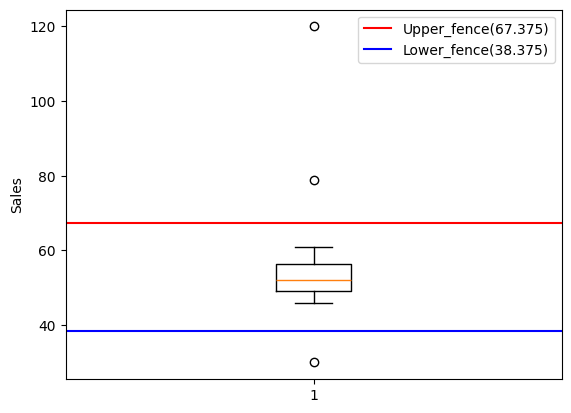

In [ ]:
# TODO ข้อ 3
sale_bp = plt.boxplot(sales,whis=1.5)
mask,lo,hi=iqr_outliers(sales)
plt.ylabel('Sales')
plt.axhline(hi, color='red', label=f"Upper_fence({hi})")
plt.axhline(lo, color='blue', label=f"Lower_fence({lo})")
plt.legend()

lower_whisker=sale_bp['whiskers'][0].get_ydata()[0]
upper_whisker=sale_bp['whiskers'][1].get_ydata()[1]
fliers=sale_bp['fliers'][0].get_ydata()


print(f'fliers:{fliers}')
print(f"upper_wisker:{upper_whisker}")
print(f"lower_wisker:{lower_whisker}")
print(f"iqr_outliers:{iqr_outliers}")

## ข้อ 4 · IQR รายกลุ่ม (contextual anomaly) (20 คะแนน)

ค่าจ้างรายเดือน (พันบาท) ของพนักงาน 3 อาชีพ อาชีพละ 8 คน

1. ใช้ `iqr_outliers` กับค่าจ้างทั้ง 24 คนรวมกัน พบ outlier กี่คน
2. ใช้ `groupby('occupation')` คำนวณ IQR แยกแต่ละอาชีพ (ใช้ `.transform` ได้) พบ outlier คนใด
3. ทำตาราง Q1, Q3, IQR, รั้วล่าง, รั้วบน ของแต่ละอาชีพ
4. อธิบายว่าทำไมผลรวมกับผลรายกลุ่มต่างกัน

In [ ]:
wage = pd.DataFrame({
    'occupation': ['cleaner']*8 + ['clerk']*8 + ['engineer']*8,
    'wage_k': [12,13,12,14,13,12,15,35,  18,20,19,22,21,20,23,9,  60,65,58,70,62,66,64,61]})

# TODO 4.1
mask, lo, hi = iqr_outliers(wage['wage_k'])
print("พบ Outlier:", mask.sum(), "คน")
# TODO 4.2
g = wage.groupby('occupation')['wage_k']
q1_g = g.transform(lambda s: np.percentile(s, 25))
q3_g = g.transform(lambda s: np.percentile(s, 75))
iqr_g = q3_g - q1_g
lo_g = q1_g - 1.5 * iqr_g
hi_g = q3_g + 1.5 * iqr_g
group_outliers = wage[(wage['wage_k'] < lo_g) | (wage['wage_k'] > hi_g)]
print("\n4.2 Outlier รายกลุ่ม:")
print(group_outliers)
# TODO 4.2–4.3
summary = g.agg(
    Q1=lambda s: np.percentile(s, 25),
    Q3=lambda s: np.percentile(s, 75)
)
summary['IQR'] = summary['Q3'] - summary['Q1']
summary['รั้วล่าง'] = summary['Q1'] - 1.5 * summary['IQR']
summary['รั้วบน'] = summary['Q3'] + 1.5 * summary['IQR']
print("\n4.3 ตารางสรุป:")
print(summary)

พบ Outlier: 0 คน

4.2 Outlier รายกลุ่ม:
   occupation  wage_k
7     cleaner      35
15      clerk       9

4.3 ตารางสรุป:
               Q1     Q3   IQR  รั้วล่าง  รั้วบน
occupation                                      
cleaner     12.00  14.25  2.25     8.625  17.625
clerk       18.75  21.25  2.50    15.000  25.000
engineer    60.75  65.25  4.50    54.000  72.000


4.4
เพราะฐานเงินเดือนของแต่ละอาชีพต่างกันมาก เมือคิดรวมกันเงินเดือนสูงๆของวิศวกรจะดึงให้เกณปกติกว้างมากขึ้น จนบังค่าที่ผิดปกติของอาชีพอื่นให้ดูเหมือน แต่พอแยกคิดตามอาชีพ เกณฑ์ปกติของแต่ละกลุ่มจะแคบลง